# Feature Selection & PCA

More features are not always better: irrelevant features add noise, slow training, increase the risk of overfitting and make models harder to explain. **Feature selection** keeps a useful subset; **dimensionality reduction** (PCA) replaces many correlated features with a few combinations.

**After this lesson you can:**

1. Use filter methods: variance, correlation, mutual information.
2. Use wrapper methods (recursive feature elimination) and embedded methods (L1, tree importances).
3. Use permutation importance on held-out data, and avoid selection bias.
4. Apply PCA, choose the number of components, and understand what is lost.

**Data:** Ames Housing (with one-hot encoded categories: about 300 features).

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
RNG = 42

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import RFECV, SelectKBest, VarianceThreshold, mutual_info_regression
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LassoCV, RidgeCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

ames = datasets.ames()
ames = ames[ames["Gr_Liv_Area"] <= 4000].reset_index(drop=True)
y = np.log(ames["Sale_Price"])
X_raw = ames.drop(columns=["Sale_Price", "Longitude", "Latitude"])
num = X_raw.select_dtypes("number").columns.tolist()
cat = X_raw.columns.difference(num).tolist()
pre = ColumnTransformer([("num", StandardScaler(), num), ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=10,
                                                                               sparse_output=False), cat)]).set_output(transform="pandas")
X = pre.fit_transform(X_raw)          # for exploration only; models below refit preprocessing inside pipelines
print(f"{len(num)} numeric + {len(cat)} categorical columns -> {X.shape[1]} features after one-hot encoding")
cv = KFold(5, shuffle=True, random_state=RNG)

32 numeric + 46 categorical columns -> 306 features after one-hot encoding


## 1. Filter Methods

Filters score each feature **alone**, without a model: fast, but blind to interactions and redundancy.

In [2]:
vt = VarianceThreshold(0.01).fit(X)
print(f"near-constant features (variance < 0.01): {(~vt.get_support()).sum()}")

corr = X.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(ascending=False)
print("most correlated feature pairs:\n", pairs.head(5).round(3).to_string())

mi = pd.Series(mutual_info_regression(X, y, random_state=RNG), index=X.columns).sort_values(ascending=False)
print("\ntop 8 by mutual information:\n", mi.head(8).round(3).to_string())

near-constant features (variance < 0.01): 73


most correlated feature pairs:
 cat__Street_Grvl            cat__Street_Pave                               1.0
cat__Garage_Cond_No_Garage  cat__Garage_Qual_No_Garage                     1.0
cat__Bsmt_Cond_No_Basement  cat__Bsmt_Qual_No_Basement                     1.0
cat__Bldg_Type_Duplex       cat__MS_SubClass_Duplex_All_Styles_and_Ages    1.0
cat__Central_Air_N          cat__Central_Air_Y                             1.0



top 8 by mutual information:
 num__Gr_Liv_Area       0.491
num__Year_Built        0.406
num__Garage_Area       0.397
num__Total_Bsmt_SF     0.397
num__Garage_Cars       0.396
num__First_Flr_SF      0.373
num__Year_Remod_Add    0.290
num__Full_Bath         0.259


## 2. Embedded Methods: L1 Regularisation

**Lasso** (L1 penalty) shrinks some coefficients exactly to zero: selection happens while the model is fitted. `LassoCV` chooses the penalty strength by cross-validation.

In [3]:
lasso = make_pipeline(pre, LassoCV(cv=5, random_state=RNG, alphas=40, max_iter=5000)).fit(X_raw, y)
coefs = pd.Series(lasso[-1].coef_, index=lasso[0].get_feature_names_out())
kept = coefs[coefs != 0]
print(f"Lasso keeps {len(kept)} of {len(coefs)} features (alpha = {lasso[-1].alpha_:.5f})")
print(kept.abs().sort_values(ascending=False).head(10).round(4).to_string())

Lasso keeps 165 of 306 features (alpha = 0.00029)
cat__Overall_Qual_infrequent_sklearn    0.3464
cat__Overall_Qual_Poor                  0.3233
cat__Functional_infrequent_sklearn      0.2270
cat__Overall_Qual_Very_Excellent        0.1619
cat__Overall_Qual_Excellent             0.1468
num__Gr_Liv_Area                        0.1342
cat__Overall_Cond_Fair                  0.1335
cat__MS_Zoning_C_all                    0.1229
cat__Exter_Cond_infrequent_sklearn      0.1196
cat__Overall_Qual_Fair                  0.1095


## 3. Wrapper Methods: Recursive Feature Elimination

**RFE** fits a model, removes the weakest features, and repeats; `RFECV` chooses the number of features by cross-validation. It is expensive but accounts for redundancy between features.

RFECV on 32 numeric features: best = 31 features (0.7 s)
selected: ['Lot_Frontage', 'Lot_Area', 'Year_Built', 'Year_Remod_Add', 'Mas_Vnr_Area', 'BsmtFin_SF_1', 'BsmtFin_SF_2', 'Bsmt_Unf_SF', 'Total_Bsmt_SF', 'First_Flr_SF', 'Second_Flr_SF', 'Low_Qual_Fin_SF', 'Gr_Liv_Area', 'Bsmt_Full_Bath', 'Bsmt_Half_Bath'] ...


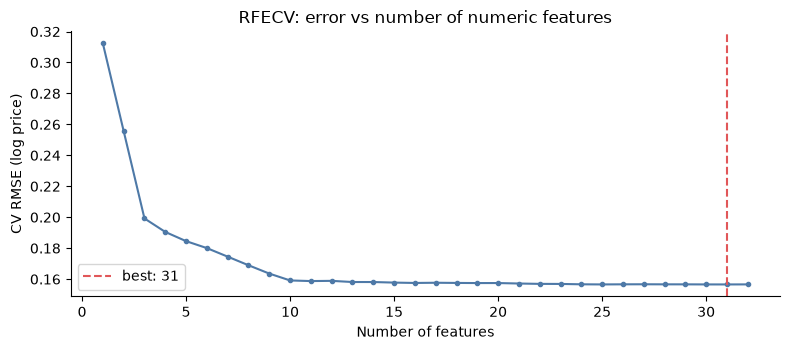

In [4]:
num_only = ames[num].fillna(0)
t = time.perf_counter()
rfe = RFECV(RidgeCV(), step=1, cv=cv, scoring="neg_root_mean_squared_error",
            importance_getter="coef_").fit(StandardScaler().fit_transform(num_only), y)
scores = -rfe.cv_results_["mean_test_score"]
print(f"RFECV on {len(num)} numeric features: best = {rfe.n_features_} features ({time.perf_counter() - t:.1f} s)")
print("selected:", [c for c, s in zip(num, rfe.support_) if s][:15], "...")

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(range(1, len(scores) + 1), scores, marker=".", color="#4E79A7")
ax.axvline(rfe.n_features_, color="#E15759", ls="--", label=f"best: {rfe.n_features_}")
ax.set(xlabel="Number of features", ylabel="CV RMSE (log price)", title="RFECV: error vs number of numeric features")
ax.legend()
plt.tight_layout()
plt.show()

The curve falls steeply for the first features and then flattens: most of the predictive power is in a small subset. The very best score uses almost all numeric features, but the gain after the first ten or so is small; a simpler model with fewer features is often the better trade-off.

## 4. Permutation Importance on Held-Out Data

**Permutation importance** shuffles one feature in the **test** data and measures how much the model gets worse. Unlike impurity-based tree importances, it does not favour high-cardinality features and reflects what the model actually uses on new data.

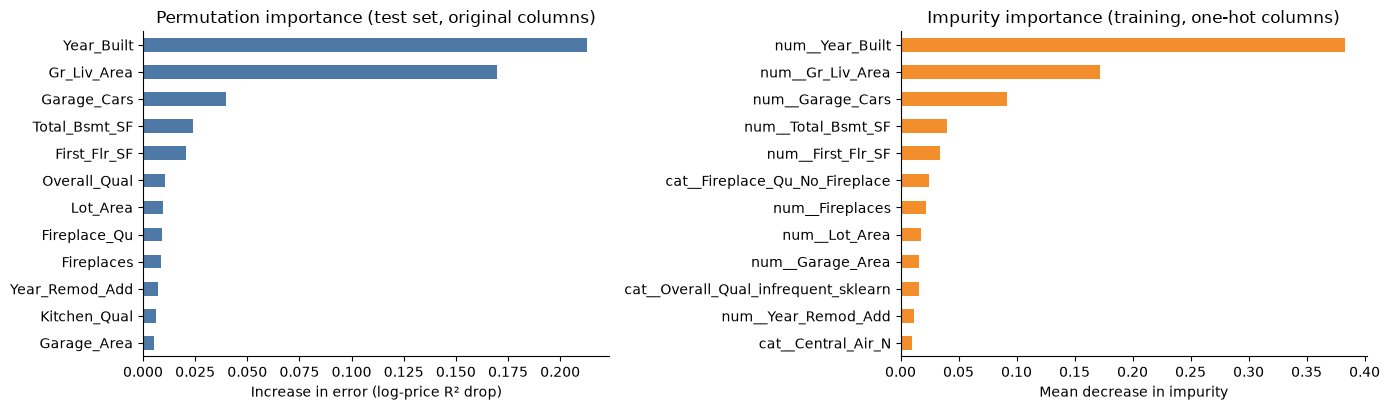

In [5]:
X_tr, X_te, y_tr, y_te = train_test_split(X_raw, y, test_size=0.25, random_state=RNG)
rf = make_pipeline(pre, RandomForestRegressor(300, n_jobs=-1, random_state=RNG, min_samples_leaf=2)).fit(X_tr, y_tr)
perm = permutation_importance(rf, X_te, y_te, n_repeats=5, random_state=RNG, n_jobs=-1)
perm_s = pd.Series(perm.importances_mean, index=X_te.columns).sort_values(ascending=False)
impurity = pd.Series(rf[-1].feature_importances_, index=rf[0].get_feature_names_out()).sort_values(ascending=False)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.2))
perm_s.head(12)[::-1].plot.barh(ax=ax1, color="#4E79A7")
ax1.set(title="Permutation importance (test set, original columns)", xlabel="Increase in error (log-price R² drop)")
impurity.head(12)[::-1].plot.barh(ax=ax2, color="#F28E2B")
ax2.set(title="Impurity importance (training, one-hot columns)", xlabel="Mean decrease in impurity")
plt.tight_layout()
plt.show()

Permutation importance works on the **original** columns (a whole categorical feature is shuffled at once), which is easier to explain than dozens of one-hot columns.

## 5. Selection Bias: Select Inside Cross-Validation

Selecting features on **all** data and then cross-validating gives an optimistic score: the selection already saw the test folds. The experiment shows it with pure noise: 1,000 random features and a random target.

In [6]:
rng = np.random.default_rng(RNG)
Xn = pd.DataFrame(rng.normal(size=(300, 1000)))
yn = pd.Series(rng.normal(size=300))
from sklearn.feature_selection import f_regression
wrong_idx = SelectKBest(f_regression, k=20).fit(Xn, yn).get_support()
wrong = cross_val_score(RidgeCV(), Xn.loc[:, wrong_idx], yn, cv=cv, scoring="r2").mean()
right = cross_val_score(make_pipeline(SelectKBest(f_regression, k=20), RidgeCV()), Xn, yn, cv=cv, scoring="r2").mean()
print(f"noise data, select on all rows, then CV : R² = {wrong:+.3f}  <- looks predictive")
print(f"noise data, selection inside the CV pipe: R² = {right:+.3f}  <- correct: nothing to predict")

noise data, select on all rows, then CV : R² = +0.218  <- looks predictive
noise data, selection inside the CV pipe: R² = -0.258  <- correct: nothing to predict


## 6. PCA: Many Correlated Features into a Few Components

**Principal component analysis** finds orthogonal directions of maximal variance. The first $k$ components often keep most of the variance of correlated features, but they are combinations of all features: harder to explain, and the directions with the most **variance** are not necessarily the most **predictive** ones.

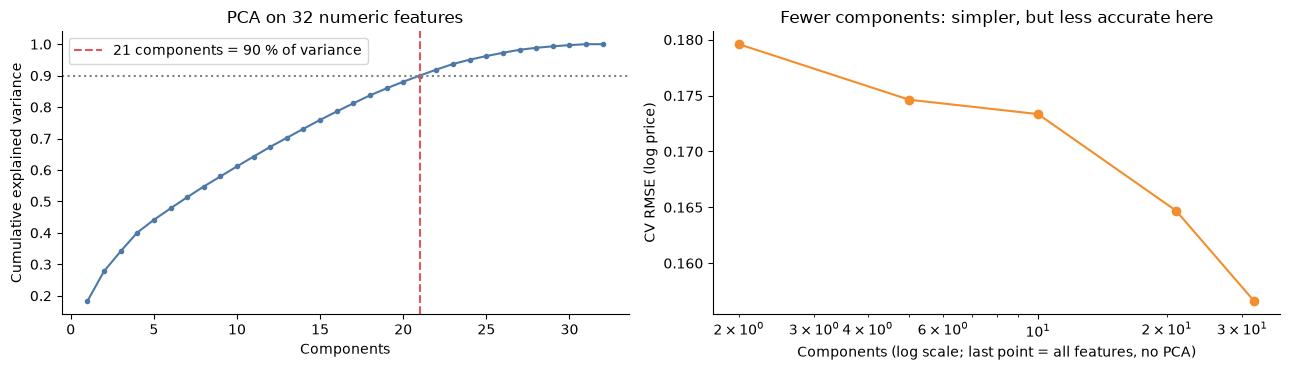

{2: np.float64(0.1796), 5: np.float64(0.1746), 10: np.float64(0.1733), 21: np.float64(0.1647), 32: np.float64(0.1566)}


In [7]:
Xnum = StandardScaler().fit_transform(ames[num].fillna(0))
pca = PCA().fit(Xnum)
cum = np.cumsum(pca.explained_variance_ratio_)
k90 = int(np.searchsorted(cum, 0.90) + 1)
res = {}
for k in [2, 5, 10, k90, len(num)]:
    m = make_pipeline(StandardScaler(), PCA(k), RidgeCV()) if k < len(num) else make_pipeline(StandardScaler(), RidgeCV())
    res[k] = -cross_val_score(m, ames[num].fillna(0), y, cv=cv, scoring="neg_root_mean_squared_error").mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
ax1.plot(range(1, len(cum) + 1), cum, marker=".", color="#4E79A7")
ax1.axhline(0.9, color="grey", ls=":")
ax1.axvline(k90, color="#E15759", ls="--", label=f"{k90} components = 90 % of variance")
ax1.set(xlabel="Components", ylabel="Cumulative explained variance", title=f"PCA on {len(num)} numeric features")
ax1.legend()
ax2.plot(list(res), list(res.values()), marker="o", color="#F28E2B")
ax2.set(xscale="log", xlabel="Components (log scale; last point = all features, no PCA)", ylabel="CV RMSE (log price)",
        title="Fewer components: simpler, but less accurate here")
plt.tight_layout()
plt.show()
print({k: round(v, 4) for k, v in res.items()})

| Method | Speed | Handles redundancy | Uses the target | Keeps interpretability |
| :--- | :--- | :--- | :--- | :--- |
| variance / correlation filters | fast | correlation only | no | yes |
| mutual information, univariate tests | fast | no | yes | yes |
| L1 (Lasso), tree importances | medium | partly | yes | yes |
| RFE / RFECV | slow | yes | yes | yes |
| permutation importance | medium | partly (correlated features share importance) | yes | yes |
| PCA | fast | yes | no | **no** (combinations) |

*Insight: Remove obviously useless features cheaply (constants, duplicates), then let regularisation or cross-validated selection do the rest, always inside the cross-validation loop. Use PCA for compression and visualisation, not as an automatic first step for prediction.*

## Real-World Use Case or Analogy

Feature selection is like **packing for a trip**: leave out what you will never use (constant columns), do not pack the same item twice (correlated features), and test-pack (cross-validation) before deciding. PCA is like **vacuum-packing**: everything fits in less space, but you cannot see individual items any more.

In genomics, models start with tens of thousands of gene measurements and a few hundred patients; careful selection inside cross-validation is the difference between a real discovery and a false one.